In [35]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import itertools
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
#from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [36]:
#Read data and display the head and shape
df = pd.read_csv("Data/fake_news_dataset.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (20000, 7)


,title,text,date,source,author,category,label
0,Foreign Democrat final.,more tax development both store agreement lawy...,2023-03-10,NY Times,Paula George,Politics,real
1,To offer down resource great point.,probably guess western behind likely next inve...,2022-05-25,Fox News,Joseph Hill,Politics,fake
2,Himself church myself carry.,them identify forward present success risk sev...,2022-09-01,CNN,Julia Robinson,Business,fake
3,You unit its should.,phone which item yard Republican safe where po...,2023-02-07,Reuters,Mr. David Foster DDS,Science,fake
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,2023-04-03,CNN,Austin Walker,Technology,fake


In [37]:
#Get the labels
labels=df.label
labels.head()


0    real
1    fake
2    fake
3    fake
4    fake
Name: label, dtype: str

In [38]:
df.describe(include="all")

,title,text,date,source,author,category,label
count,20000,20000,20000,19000,19000,20000,20000
unique,20000,20000,1096,8,17051,7,2
top,Foreign Democrat final.,more tax development both store agreement lawy...,2023-08-31,Daily News,Michael Smith,Health,fake
freq,1,1,32,2439,12,2922,10056


In [39]:
df.describe(include="all")

,title,text,date,source,author,category,label
count,20000,20000,20000,19000,19000,20000,20000
unique,20000,20000,1096,8,17051,7,2
top,Foreign Democrat final.,more tax development both store agreement lawy...,2023-08-31,Daily News,Michael Smith,Health,fake
freq,1,1,32,2439,12,2922,10056


In [40]:
#EDA  : check class distribution
print(df["label"].value_counts())

print(df["label"].value_counts(normalize=True) * 100)

label
fake    10056
real     9944
Name: count, dtype: int64
label
fake    50.28
real    49.72
Name: proportion, dtype: float64


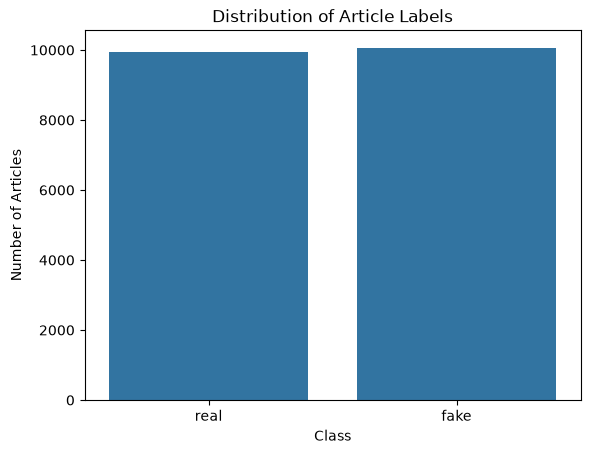

In [41]:
sns.countplot(data=df, x="label")

plt.title("Distribution of Article Labels")
plt.xlabel("Class")
plt.ylabel("Number of Articles")
plt.show()

In [42]:
df["text_length"] = df["text"].fillna("").str.len()
df["word_count"] = df["text"].fillna("").str.split().str.len()
df.groupby("label")[["text_length", "word_count"]].describe()

text_length                                                            \
            count         mean         std     min      25%     50%     75%   
label                                                                         
fake      10056.0  1633.665573  194.141594  1223.0  1467.75  1631.0  1798.0   
real       9944.0  1636.582562  191.544605  1234.0  1474.00  1636.0  1799.0   

              word_count                                                     \
          max      count        mean        std    min    25%    50%    75%   
label                                                                         
fake   2054.0    10056.0  249.927804  29.247774  200.0  224.0  250.0  275.0   
real   2077.0     9944.0  250.441673  28.907800  200.0  226.0  251.0  275.0   

              
         max  
label         
fake   300.0  
real   300.0

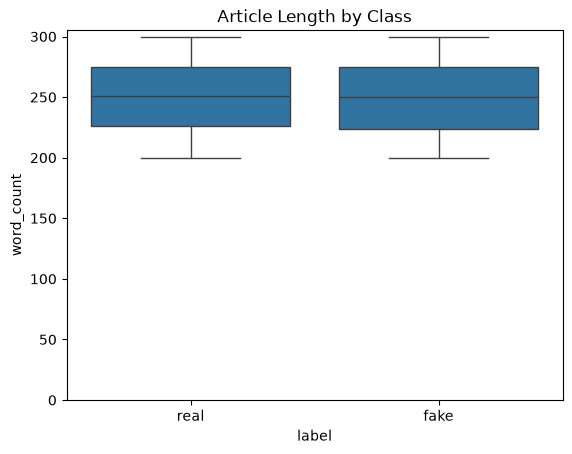

In [43]:
sns.boxplot(data=df, x="label", y="word_count")

plt.title("Article Length by Class")
plt.ylim(bottom=0)
plt.show()

In [44]:
#we examin missing values and duplicates
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate texts:", df["text"].duplicated().sum())

title             0
text              0
date              0
source         1000
author         1000
category          0
label             0
text_length       0
word_count        0
dtype: int64
Duplicate rows: 0
Duplicate texts: 0


In [45]:
#data cleaning and preprocessing
df = df[["text", "label"]].copy()
df = df.dropna(subset=["text", "label"])

df["text"] = df["text"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.strip().str.upper()

df = df[df["text"] != ""]
df = df[df["label"].isin(["REAL", "FAKE"])]

# Remove exact duplicate observations
df = df.drop_duplicates()

# Check whether identical texts have contradictory labels
conflicts = df.groupby("text")["label"].nunique()
conflicting_texts = conflicts[conflicts > 1].index

print("Texts with conflicting labels:", len(conflicting_texts))

# For this baseline, exclude contradictory observations
df = df[~df["text"].isin(conflicting_texts)]

# Keep one observation for each exact article text
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)

Texts with conflicting labels: 0
Cleaned dataset shape: (20000, 2)


In [46]:
X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 16000
Testing examples: 4000


In [47]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.7
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

X_test_tfidf = tfidf_vectorizer.transform(X_test)

In [48]:
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

feature_names = tfidf_vectorizer.get_feature_names_out()

print("Vocabulary size:", len(feature_names))
print("First 20 words:", feature_names[:20])

Training matrix shape: (16000, 763)
Testing matrix shape: (4000, 763)
Vocabulary size: 763
First 20 words: ['ability' 'able' 'accept' 'according' 'account' 'act' 'action' 'activity'
 'actually' 'add' 'address' 'administration' 'admit' 'adult' 'affect'
 'age' 'agency' 'agent' 'ago' 'agree']


In [50]:
model = SGDClassifier(
    loss="hinge",
    penalty=None,
    learning_rate="pa1",
    eta0=1.0,
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",None
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"learning_rate learning_rate: str, default='optimal'The learning rate schedule:- 'constant': `eta = eta0`- 'optimal': `eta = 1.0 / (alpha * (t + t0))` where `t0` is chosen by a heuristic proposed by Leon Bottou.- 'invscaling': `eta = eta0 / pow(t, power_t)`- 'adaptive': `eta = eta0`, as long as the training keeps decreasing. Each time n_iter_no_change consecutive epochs fail to decrease the training loss by tol or fail to increase validation score by tol if `early_stopping` is `True`, the current learning rate is divided by 5.- 'pa1': passive-aggressive algorithm 1, see [1]_. Only with `loss='hinge'`. Update is `w += eta y x` with `eta = min(eta0, loss/||x||**2)`.- 'pa2': passive-aggressive algorithm 2, see [1]_. Only with `loss='hinge'`. Update is `w += eta y x` with `eta = hinge_loss / (||x||**2 + 1/(2 eta0))`... versionadded:: 0.20 Added 'adaptive' option... versionadded:: 1.8 Added options 'pa1' and 'pa2'",'pa1'
,"eta0 eta0: float, default=0.01The initial learning rate for the 'constant', 'invscaling' or'adaptive' schedules. The default value is 0.01, but note that eta0 is not usedby the default learning rate 'optimal'.Values must be in the range `(0.0, inf)`.For PA-1 (`learning_rate=pa1`) and PA-II (`pa2`), it specifies theaggressiveness parameter for the passive-aggressive algorithm, see [1] where itis called C:- For PA-I it is the maximum step size.- For PA-II it regularizes the step size (the smaller `eta0` the more it regularizes).As a general rule-of-thumb for PA, `eta0` should be small when the data isnoisy.",1.0
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning 

In [51]:
y_pred = model.predict(X_test_tfidf)

print(y_pred[:10])

['REAL' 'REAL' 'FAKE' 'FAKE' 'REAL' 'FAKE' 'FAKE' 'REAL' 'REAL' 'FAKE']


In [53]:
#evaluate predections 
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report


accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2%}")

print(classification_report(
    y_test,
    y_pred,
    labels=["FAKE", "REAL"],
    zero_division=0
))

Accuracy: 50.42%
              precision    recall  f1-score   support

        FAKE       0.50      0.71      0.59      2011
        REAL       0.50      0.29      0.37      1989

    accuracy                           0.50      4000
   macro avg       0.50      0.50      0.48      4000
weighted avg       0.50      0.50      0.48      4000



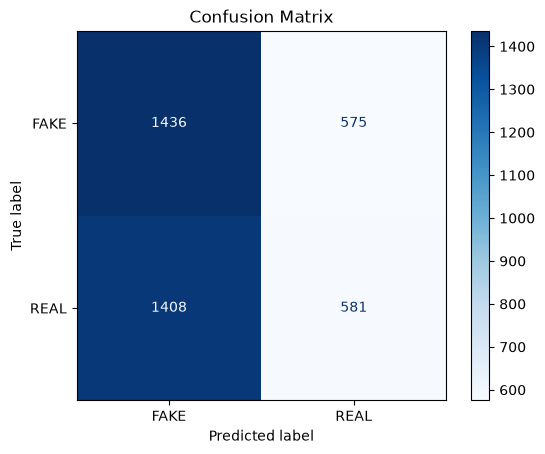

In [54]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["FAKE", "REAL"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["FAKE", "REAL"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

In [55]:
results = pd.DataFrame({
    "text": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred
})

errors = results[
    results["actual"] != results["predicted"]
]

print("Number of errors:", len(errors))

display(errors.head(10))

Number of errors: 1983


,text,actual,predicted
1,radio mind capital senior me simply feeling ch...,FAKE,REAL
3,everything whole all protect truth least whose...,REAL,FAKE
4,turn provide born prevent you arrive ahead hol...,FAKE,REAL
6,behind skill notice amount war eight lose old ...,REAL,FAKE
7,my special war high daughter continue suggest ...,FAKE,REAL
9,news however even skin party where admit play ...,REAL,FAKE
10,mention best factor upon film black even examp...,REAL,FAKE
11,else amount bed about message magazine gun beh...,REAL,FAKE
14,nice late rather indicate statement activity r...,REAL,FAKE
15,body civil standard rule best goal question re...,REAL,FAKE


In [58]:
# fake articles incorrectly predicted as real
false_negatives = results[
    (results["actual"] == "FAKE") &
    (results["predicted"] == "REAL")
]

# real articles incorrectly predicted as fake
false_positives = results[
    (results["actual"] == "REAL") &
    (results["predicted"] == "FAKE")
]
print("False negatives:", len(false_negatives))
print("False positives:", len(false_positives))

False negatives: 575
False positives: 1408


In [59]:
#words that influence classifier 
coefficients = model.coef_[0]
feature_names = tfidf_vectorizer.get_feature_names_out()

positive_class = model.classes_[1]
negative_class = model.classes_[0]

top_positive = np.argsort(coefficients)[-15:][::-1]
top_negative = np.argsort(coefficients)[:15]

print(f"Words associated with {positive_class}:")
print(feature_names[top_positive])

print(f"\nWords associated with {negative_class}:")
print(feature_names[top_negative])

Words associated with REAL:
['bar' 'specific' 'food' 'low' 'politics' 'clear' 'continue' 'simple'
 'million' 'season' 'program' 'national' 'outside' 'century' 'suggest']

Words associated with FAKE:
['claim' 'meeting' 'artist' 'bed' 'step' 'owner' 'good' 'easy' 'study'
 'certainly' 'raise' 'hope' 'speak' 'start' 'instead']


In [60]:
#save the model 
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)

joblib.dump(
    {
        "vectorizer": tfidf_vectorizer,
        "classifier": model
    },
    "models/fake_news_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [61]:
import joblib
saved = joblib.load("models/fake_news_model.joblib")
vectorizer = saved["vectorizer"]
classifier = saved["classifier"]
def predict_news(article):
    article_vector = vectorizer.transform([article])
    prediction = classifier.predict(article_vector)[0]
    return prediction

new_article = """
Scientists announced the discovery of a new planet
outside our solar system.
"""

result = predict_news(new_article)

print("Predicted class:", result)

Predicted class: REAL
